# Banknote Authentication with k-Nearest Neighbors from Scratch

## Exploratory Data Analysis

This notebook explores the UCI Banknote Authentication dataset before building a k-Nearest Neighbors classifier from scratch.

The main goals are to:
- understand the structure of the dataset,
- inspect the target class distribution,
- analyze the numerical features,
- identify potential preprocessing requirements before modeling.

In [1]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt

In [2]:
columns = ["variance", "skewness", "curtosis", "entropy", "class"]

In [3]:
project_root = Path.cwd()

if project_root.name == "notebooks":
    project_root = project_root.parent

data_path = project_root / "data" / "raw" / "data_banknote_authentication.txt"

print(data_path)

/Users/oliversulej/Desktop/github_projects/banknote-authentication-from-scratch/data/raw/data_banknote_authentication.txt


In [4]:
column_names = [
    "variance",
    "skewness",
    "curtosis",
    "entropy",
    "class"
]

In [5]:
df = pd.read_csv(data_path, names=column_names)

## Initial Data Inspection

We first inspect the structure of the dataset and verify that it has been loaded correctly.

In [6]:
df.head()

,variance,skewness,curtosis,entropy,class
0,3.62160,8.6661,-2.8073,-0.44699,0
1,4.54590,8.1674,-2.4586,-1.46210,0
2,3.86600,-2.6383,1.9242,0.10645,0
3,3.45660,9.5228,-4.0112,-3.59440,0
4,0.32924,-4.4552,4.5718,-0.98880,0


In [7]:
df.shape

(1372, 5)

In [8]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1372 entries, 0 to 1371
Data columns (total 5 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   variance  1372 non-null   float64
 1   skewness  1372 non-null   float64
 2   curtosis  1372 non-null   float64
 3   entropy   1372 non-null   float64
 4   class     1372 non-null   int64  
dtypes: float64(4), int64(1)
memory usage: 53.7 KB


## Missing Values

We check whether any observations contain missing values before continuing with the analysis.

In [9]:
missing_values = df.isna().sum()

missing_values

variance    0
skewness    0
curtosis    0
entropy     0
class       0
dtype: int64

## Target Class Distribution

Before building a classifier, we inspect whether the target classes are balanced.

In [10]:
class_counts = df["class"].value_counts()
class_counts

class
0    762
1    610
Name: count, dtype: int64

In [11]:
class_proportions = df["class"].value_counts(normalize=True)
class_proportions

class
0    0.555394
1    0.444606
Name: proportion, dtype: float64

## Descriptive Statistics

We summarize the numerical variables to understand their ranges, variability, and central tendencies.

In [12]:
df.describe()

,variance,skewness,curtosis,entropy,class
count,1372.000000,1372.000000,1372.000000,1372.000000,1372.000000
mean,0.433735,1.922353,1.397627,-1.191657,0.444606
std,2.842763,5.869047,4.310030,2.101013,0.497103
min,-7.042100,-13.773100,-5.286100,-8.548200,0.000000
25%,-1.773000,-1.708200,-1.574975,-2.413450,0.000000
50%,0.496180,2.319650,0.616630,-0.586650,0.000000
75%,2.821475,6.814625,3.179250,0.394810,1.000000
max,6.824800,12.951600,17.927400,2.449500,1.000000


In [13]:
df.shape

(1372, 5)

## Target Class Distribution

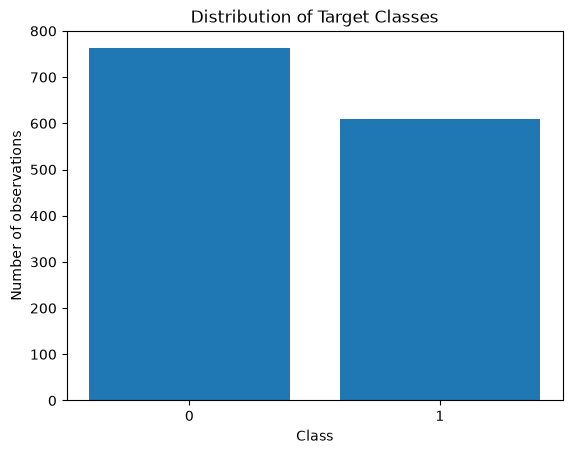

In [14]:
class_counts = df["class"].value_counts().sort_index()

fig, ax = plt.subplots()

ax.bar(class_counts.index, class_counts.values)

ax.set_xlabel("Class")
ax.set_ylabel("Number of observations")
ax.set_title("Distribution of Target Classes")
ax.set_xticks([0, 1])

plt.show()

The dataset is relatively balanced, with approximately 56% of observations belonging to class 0 and 44% to class 1. Therefore, class imbalance is unlikely to dominate the evaluation of the classifier.

In [15]:
class_0_data = df[df["class"] == 0]
class_1_data = df[df["class"] == 1]

variance_0 = class_0_data["variance"].mean()
variance_1 = class_1_data["variance"].mean()

print(f"Mean variance for class 0: {variance_0:.4f}")
print(f"Mean variance for class 1: {variance_1:.4f}")

Mean variance for class 0: 2.2767
Mean variance for class 1: -1.8684


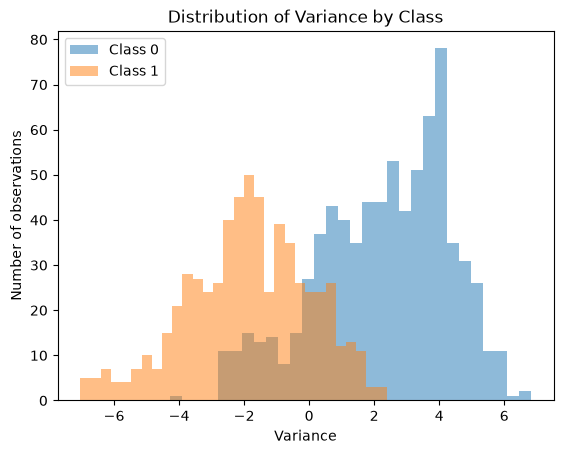

In [16]:
fig, ax = plt.subplots()


ax.hist(class_0_data["variance"], bins=30, alpha=0.5, label="Class 0")
ax.hist(class_1_data["variance"], bins=30, alpha=0.5, label="Class 1")


ax.set_xlabel("Variance")
ax.set_ylabel("Number of observations")
ax.set_title("Distribution of Variance by Class")
ax.legend()

plt.show()

Class 0 variance mean:  2.276686005249344
Class 1 variance mean:  -1.8684425627868853


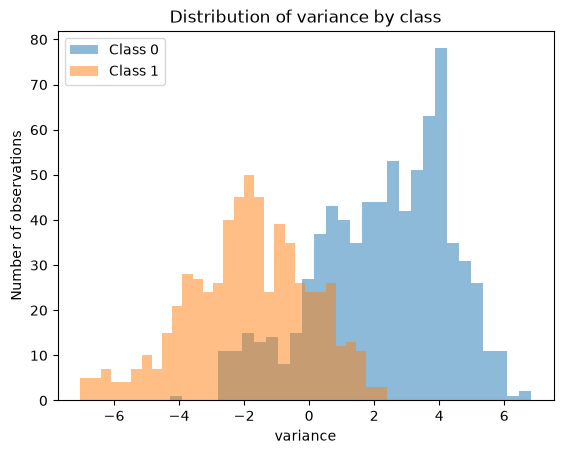

Class 0 skewness mean:  4.256627188342782
Class 1 skewness mean:  -0.9935761245901639


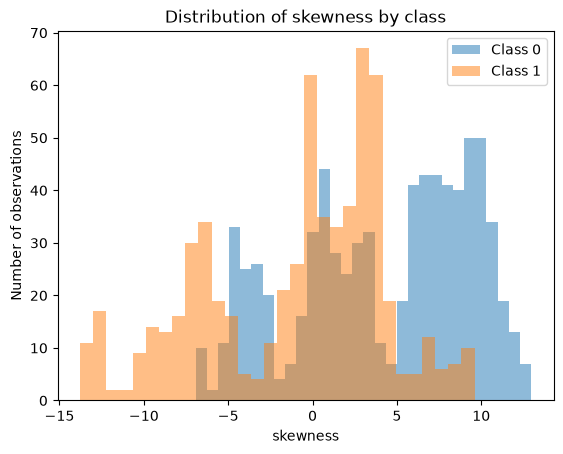

Class 0 curtosis mean:  0.7967179652099738
Class 1 curtosis mean:  2.148271008852459


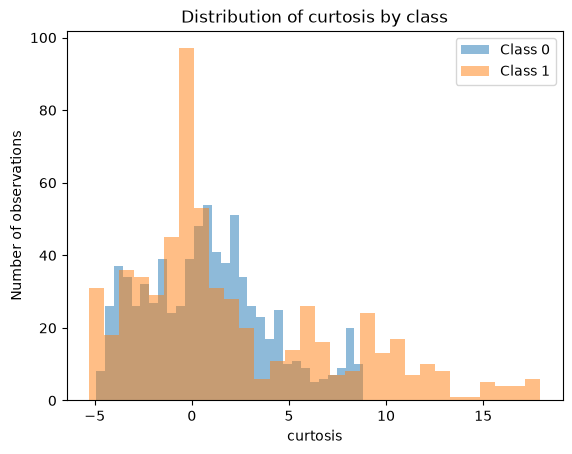

Class 0 entropy mean:  -1.1476402762467193
Class 1 entropy mean:  -1.2466407459016393


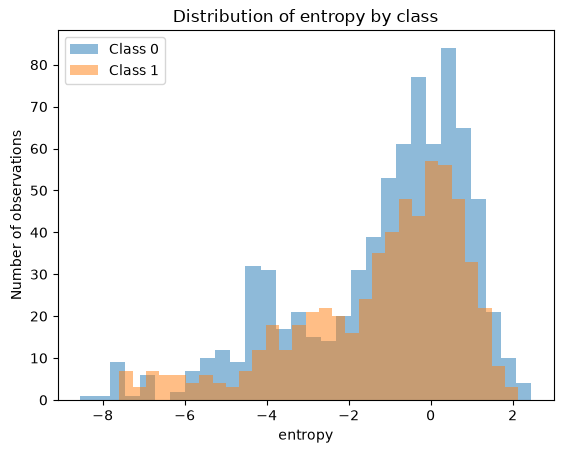

In [17]:
feature_names = ["variance", "skewness", "curtosis", "entropy"]
for feature in feature_names:
    print(f"Class 0 {feature} mean:  {class_0_data[feature].mean()}")
    print(f"Class 1 {feature} mean:  {class_1_data[feature].mean()}")

    fig, ax = plt.subplots()

    ax.hist(class_0_data[feature], bins= 30, alpha= 0.5, label="Class 0")
    ax.hist(class_1_data[feature], bins= 30, alpha= 0.5, label="Class 1")

    ax.set_xlabel(feature)
    ax.set_ylabel("Number of observations")
    ax.set_title(f"Distribution of {feature} by class")
    ax.legend()

    plt.show()

### Feature Distribution Analysis — Conclusion

The feature distributions show noticeable differences between the two target classes. The strongest separation can be observed for `variance` and `skewness`, where the distributions and mean values differ considerably between class 0 and class 1.

`curtosis` also appears to contain useful information, although the distributions of the two classes overlap more strongly. In contrast, `entropy` shows relatively similar distributions and mean values for both classes, suggesting that it may be less informative when considered on its own.

However, these features should not be evaluated only individually. A feature that provides limited separation by itself may still improve classification when combined with other features. Therefore, all four features will initially be retained for the kNN model.

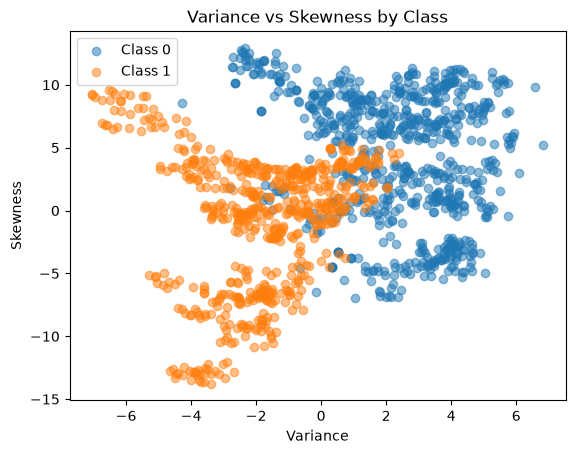

In [18]:
fig, ax = plt.subplots()

ax.scatter(
    class_0_data["variance"],
    class_0_data["skewness"],
    alpha=0.5,
    label="Class 0"
)

ax.scatter(
    class_1_data["variance"],
    class_1_data["skewness"],
    alpha=0.5,
    label="Class 1"
)

ax.set_xlabel("Variance")
ax.set_ylabel("Skewness")
ax.set_title("Variance vs Skewness by Class")
ax.legend()

figures_path = project_root / "figures"

fig.savefig(
    figures_path / "variance_skewness_scatter.png",
    dpi=150,
    bbox_inches="tight"
)

plt.show()

### Variance vs Skewness — Interpretation

The scatter plot shows that the two classes occupy noticeably different regions in the `variance`–`skewness` feature space. Class 0 observations are more concentrated at higher variance values and generally higher skewness, while class 1 observations tend to appear at lower variance values and more negative skewness values.

The classes are not perfectly separable in two dimensions, as there is a visible overlapping region. This suggests that using multiple features together may improve classification performance compared with relying on a single feature.

## Preparing Features and Target

Before building the classifier, we separate the input features from the target variable.

The feature matrix `X` contains the four numerical attributes:
- `variance`
- `skewness`
- `curtosis`
- `entropy`

The target vector `y` contains the `class` labels that the model will try to predict.

This separation is a standard step in supervised machine learning, where the model learns the relationship between input features and known target values.

In [19]:
features_names = ["variance", "skewness", "curtosis", "entropy"]

X = df[features_names]
y = df["class"]

X.shape
y.shape


(1372,)